# 05 - K-Nearest Neighbors (KNN)

Part of the **Data Science Learning** project. Explanations, comments, and notebook messages are in English.

## Learning objectives
Explore neighbor-based classification and the importance of scaling.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes, make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

In [2]:
dataset = load_breast_cancer(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(dataset.data, dataset.target, test_size=0.2, random_state=RANDOM_STATE, stratify=dataset.target)

## Compare different values of k

,k,accuracy,f1
0,1,0.938596,0.951049
1,2,0.929825,0.942857
2,3,0.982456,0.986301
3,4,0.947368,0.957746
4,5,0.956140,0.965517
5,6,0.956140,0.965035
6,7,0.973684,0.979592
7,8,0.973684,0.979310
8,9,0.973684,0.979592
9,10,0.964912,0.972603


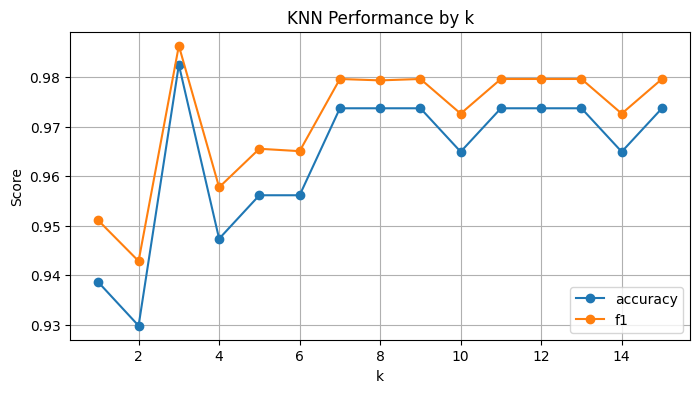

In [3]:
from sklearn.neighbors import KNeighborsClassifier

rows = []
for k in range(1, 16):
    model = Pipeline([("scaler", StandardScaler()), ("classifier", KNeighborsClassifier(n_neighbors=k))])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"k": k, "accuracy": accuracy_score(y_test, pred), "f1": f1_score(y_test, pred)})

results = pd.DataFrame(rows)
display(results)
results.set_index("k").plot(marker="o", figsize=(8, 4), title="KNN Performance by k")
plt.ylabel("Score")
plt.grid(True)
plt.show()

## Key takeaways
- KNN predicts from nearby training examples.
- Small `k` can be sensitive to noise; large `k` can smooth local patterns.
- Scaling matters because KNN uses distances.

## Exercises
1. Try Manhattan distance.
2. Use cross-validation to select `k`.